In [1]:
!pip install -q torch-geometric

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 26.6 MB/s eta 0:00:00


In [3]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch_geometric.datasets import TUDataset
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GCNConv, global_mean_pool

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

os.makedirs("results", exist_ok=True)

print("Libraries imported successfully!")
print("PyTorch version:", torch.__version__)

Libraries imported successfully!
PyTorch version: 2.11.0+cpu


In [4]:
dataset = TUDataset(root="/content/data", name="MUTAG")

print("Number of graphs:", len(dataset))
print("Node features:", dataset.num_node_features)
print("Number of classes:", dataset.num_classes)
print("First graph:", dataset[0])

Number of graphs: 188
Node features: 7
Number of classes: 2
First graph: Data(edge_index=[2, 38], x=[17, 7], edge_attr=[38, 4], y=[1])


In [5]:
# Small example: three nodes connected in a chain
A = np.array([
    [0, 1, 0],
    [1, 0, 1],
    [0, 1, 0]
], dtype=float)

# Step 1: Add self-loops
A_tilde = A + np.eye(3)

# Step 2: Calculate degree matrix
degrees = A_tilde.sum(axis=1)
D_inv_sqrt = np.diag(1 / np.sqrt(degrees))

# Step 3: Normalize adjacency matrix
A_norm = D_inv_sqrt @ A_tilde @ D_inv_sqrt

# Step 4: Example node features
H = np.array([
    [1.0],
    [2.0],
    [3.0]
])

# Step 5: Use a simple weight value
W = np.array([[2.0]])

# Step 6: Perform graph convolution before activation
Z = A_norm @ H @ W

# Step 7: Apply ReLU
H_next = np.maximum(0, Z)

print("Original adjacency matrix:\n", A)
print("\nAdjacency with self-loops:\n", A_tilde)
print("\nDegree values:", degrees)
print("\nNormalized adjacency matrix:\n", np.round(A_norm, 4))
print("\nInput features:\n", H)
print("\nWeight matrix:\n", W)
print("\nOutput before ReLU:\n", np.round(Z, 4))
print("\nOutput after ReLU:\n", np.round(H_next, 4))

Original adjacency matrix:
 [[0. 1. 0.]
 [1. 0. 1.]
 [0. 1. 0.]]

Adjacency with self-loops:
 [[1. 1. 0.]
 [1. 1. 1.]
 [0. 1. 1.]]

Degree values: [2. 3. 2.]

Normalized adjacency matrix:
 [[0.5    0.4082 0.    ]
 [0.4082 0.3333 0.4082]
 [0.     0.4082 0.5   ]]

Input features:
 [[1.]
 [2.]
 [3.]]

Weight matrix:
 [[2.]]

Output before ReLU:
 [[2.633 ]
 [4.5993]
 [4.633 ]]

Output after ReLU:
 [[2.633 ]
 [4.5993]
 [4.633 ]]


In [6]:
labels = np.array([graph.y.item() for graph in dataset])
indices = np.arange(len(dataset))

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=SEED,
    stratify=labels
)

train_dataset = [dataset[int(i)] for i in train_idx]
test_dataset = [dataset[int(i)] for i in test_idx]

train_loader = DataLoader(
    train_dataset, batch_size=32, shuffle=True
)

test_loader = DataLoader(
    test_dataset, batch_size=32, shuffle=False
)

print("Total graphs:", len(dataset))
print("Training graphs:", len(train_dataset))
print("Testing graphs:", len(test_dataset))

Total graphs: 188
Training graphs: 150
Testing graphs: 38


In [7]:
class VanillaGCN(nn.Module):
    def __init__(self, input_features, hidden_features, num_classes):
        super().__init__()

        self.gcn1 = GCNConv(input_features, hidden_features)
        self.gcn2 = GCNConv(hidden_features, hidden_features)

        self.classifier = nn.Linear(
            hidden_features, num_classes
        )

    def forward(self, data):
        x = data.x
        edge_index = data.edge_index
        batch = data.batch

        # First graph convolution
        x = self.gcn1(x, edge_index)
        x = F.relu(x)

        # Second graph convolution
        x = self.gcn2(x, edge_index)
        x = F.relu(x)

        # Convert node embeddings into graph embeddings
        x = global_mean_pool(x, batch)

        # Predict the graph class
        x = self.classifier(x)

        return x


model = VanillaGCN(
    input_features=dataset.num_node_features,
    hidden_features=16,
    num_classes=dataset.num_classes
)

print(model)

VanillaGCN(
  (gcn1): GCNConv(7, 16)
  (gcn2): GCNConv(16, 16)
  (classifier): Linear(in_features=16, out_features=2, bias=True)
)


In [8]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.01,
    weight_decay=0.0005
)

EPOCHS = 100
loss_history = []

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0

    for data in train_loader:
        optimizer.zero_grad()

        outputs = model(data)
        loss = criterion(outputs, data.y.view(-1))

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * data.num_graphs

    epoch_loss = total_loss / len(train_dataset)
    loss_history.append(epoch_loss)

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch [{epoch + 1}/{EPOCHS}], "
            f"Loss: {epoch_loss:.4f}"
        )

print("Training completed!")

Epoch [10/100], Loss: 0.5627
Epoch [20/100], Loss: 0.4864
Epoch [30/100], Loss: 0.4777
Epoch [40/100], Loss: 0.4740
Epoch [50/100], Loss: 0.4710
Epoch [60/100], Loss: 0.4710
Epoch [70/100], Loss: 0.4879
Epoch [80/100], Loss: 0.4704
Epoch [90/100], Loss: 0.4676
Epoch [100/100], Loss: 0.4723
Training completed!


In [9]:
model.eval()

actual = []
predictions = []

with torch.no_grad():
    for data in test_loader:
        outputs = model(data)
        predicted = outputs.argmax(dim=1)

        actual.extend(data.y.view(-1).cpu().numpy())
        predictions.extend(predicted.cpu().numpy())

actual = np.array(actual)
predictions = np.array(predictions)

accuracy = accuracy_score(actual, predictions)
precision = precision_score(
    actual, predictions, zero_division=0
)
recall = recall_score(
    actual, predictions, zero_division=0
)
f1 = f1_score(
    actual, predictions, zero_division=0
)

print("\nVANILLA GCN - MUTAG RESULTS")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    actual, predictions, zero_division=0
))

cm = confusion_matrix(actual, predictions, labels=[0, 1])
print("Confusion Matrix:\n", cm)


VANILLA GCN - MUTAG RESULTS
Accuracy : 0.6842
Precision: 0.7241
Recall   : 0.8400
F1-score : 0.7778

Classification Report:
              precision    recall  f1-score   support

           0       0.56      0.38      0.45        13
           1       0.72      0.84      0.78        25

    accuracy                           0.68        38
   macro avg       0.64      0.61      0.62        38
weighted avg       0.67      0.68      0.67        38

Confusion Matrix:
 [[ 5  8]
 [ 4 21]]


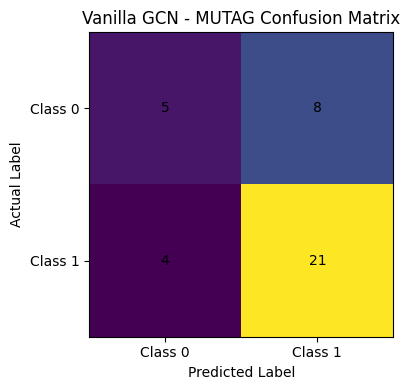

In [10]:
plt.figure(figsize=(5, 4))
plt.imshow(cm, interpolation="nearest")
plt.title("Vanilla GCN - MUTAG Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.xticks([0, 1], ["Class 0", "Class 1"])
plt.yticks([0, 1], ["Class 0", "Class 1"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, str(cm[i, j]),
                 ha="center", va="center")

plt.tight_layout()
plt.savefig("results/confusion_matrix.png", dpi=300)
plt.show()

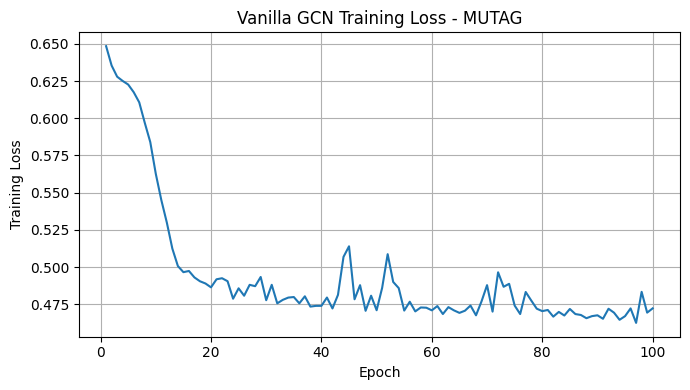

In [11]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, EPOCHS + 1), loss_history)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Vanilla GCN Training Loss - MUTAG")
plt.grid(True)
plt.tight_layout()

plt.savefig("results/training_loss.png", dpi=300)
plt.show()

In [12]:
torch.save(
    model.state_dict(),
    "results/vanilla_gcn_mutag.pth"
)

with open("results/metrics.txt", "w") as file:
    file.write("Vanilla GCN - MUTAG Case Study\n")
    file.write(f"Total graphs: {len(dataset)}\n")
    file.write(f"Training graphs: {len(train_dataset)}\n")
    file.write(f"Testing graphs: {len(test_dataset)}\n")
    file.write(f"Accuracy: {accuracy:.4f}\n")
    file.write(f"Precision: {precision:.4f}\n")
    file.write(f"Recall: {recall:.4f}\n")
    file.write(f"F1-score: {f1:.4f}\n")
    file.write(f"Confusion matrix:\n{cm}\n")

print("Saved model, metrics, and plots.")
print(os.listdir("results"))

Saved model, metrics, and plots.
['confusion_matrix.png', 'metrics.txt', 'training_loss.png', 'vanilla_gcn_mutag.pth']
